In [33]:
# Airlines EDA Project
# Step 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Airlines EDA Project Started Successfully!")


Airlines EDA Project Started Successfully!


In [34]:
# Step 2: Load the airline dataset

from pathlib import Path

data_path = Path("data/train.csv")

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Number of rows: 103904
Number of columns: 25


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [35]:

# Step 3: Explore dataset structure

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Column names:
['Unnamed: 0', 'id', 'Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'satisfaction']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  str    
 3   Customer Type                      103904 non-null  str    
 

Unnamed: 0                             0
id                                     0
Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Inflight service                       0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             310
satisfaction    


Duplicate rows: 0


In [36]:
# Step 4.5: Handle missing arrival delays

df_clean = df.copy()

# Remove unnecessary index column
if "Unnamed: 0" in df_clean.columns:
    df_clean = df_clean.drop(columns=["Unnamed: 0"])

# Fill missing arrival delays with the median
arrival_delay_median = df_clean["Arrival Delay in Minutes"].median()

df_clean["Arrival Delay in Minutes"] = (
    df_clean["Arrival Delay in Minutes"].fillna(arrival_delay_median)
)

print("Missing values after cleaning:")
print(df_clean.isnull().sum().sum())

print("Rows after cleaning:", df_clean.shape[0])
print("Columns after cleaning:", df_clean.shape[1])
print("Median arrival delay used:", arrival_delay_median)



Missing values after cleaning:
0
Rows after cleaning: 103904
Columns after cleaning: 24
Median arrival delay used: 0.0


In [37]:
# Step 4.6: Check duplicate records

print("Duplicate rows:", df_clean.duplicated().sum())
print("Unique passenger IDs:", df_clean["id"].nunique())


Duplicate rows: 0
Unique passenger IDs: 103904


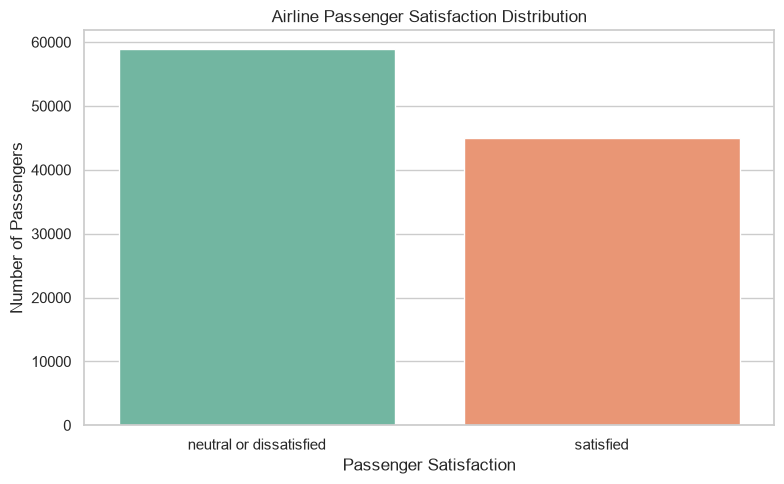

In [38]:
# Step 5: Passenger satisfaction distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="satisfaction",
    hue="satisfaction",
    palette="Set2",
    legend=False
)

plt.title("Airline Passenger Satisfaction Distribution")
plt.xlabel("Passenger Satisfaction")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()


### Graph 1: Airline Passenger Satisfaction Distribution

**Observation:** The chart shows that neutral or dissatisfied passengers outnumber satisfied passengers.

**Interpretation:** Approximately 56.5% of passengers are neutral or dissatisfied, while around 43.5% are satisfied.

**Business Insight:** The airline should investigate which aspects of the passenger experience are associated with lower satisfaction, such as in-flight services, online boarding, and flight delays.

**Recommendation:** Analyze service ratings and delay patterns to identify the areas that need improvement.

satisfaction,neutral or dissatisfied,satisfied
Class,,
Business,30.57,69.43
Eco,81.39,18.61
Eco Plus,75.39,24.61


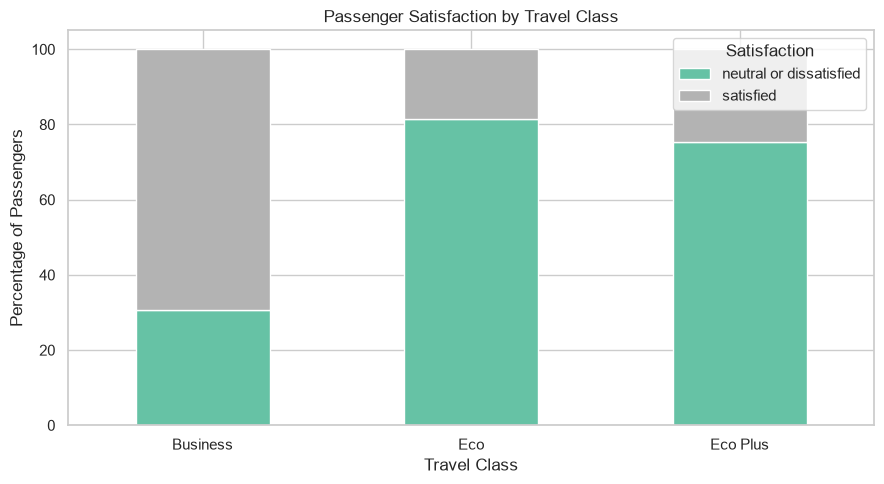

In [39]:

# Graph 2: Passenger Satisfaction by Travel Class

class_satisfaction = pd.crosstab(
    df_clean["Class"],
    df_clean["satisfaction"],
    normalize="index"
) * 100

display(class_satisfaction.round(2))

class_satisfaction.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    colormap="Set2"
)

plt.title("Passenger Satisfaction by Travel Class")
plt.xlabel("Travel Class")
plt.ylabel("Percentage of Passengers")
plt.legend(title="Satisfaction")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()


### Graph 2: Passenger Satisfaction by Travel Class

**Observation:** Passenger satisfaction differs significantly across travel classes.

**Interpretation:** Business Class has the highest proportion of satisfied passengers, while Eco Class has the lowest. Eco Plus also shows a lower satisfaction level than Business Class.

**Business Insight:** The airline should investigate which service factors contribute to the satisfaction gap between Business and Economy passengers.

**Recommendation:** Review economy-class services, including seat comfort, online boarding, food quality, and in-flight entertainment, to identify improvement opportunities.

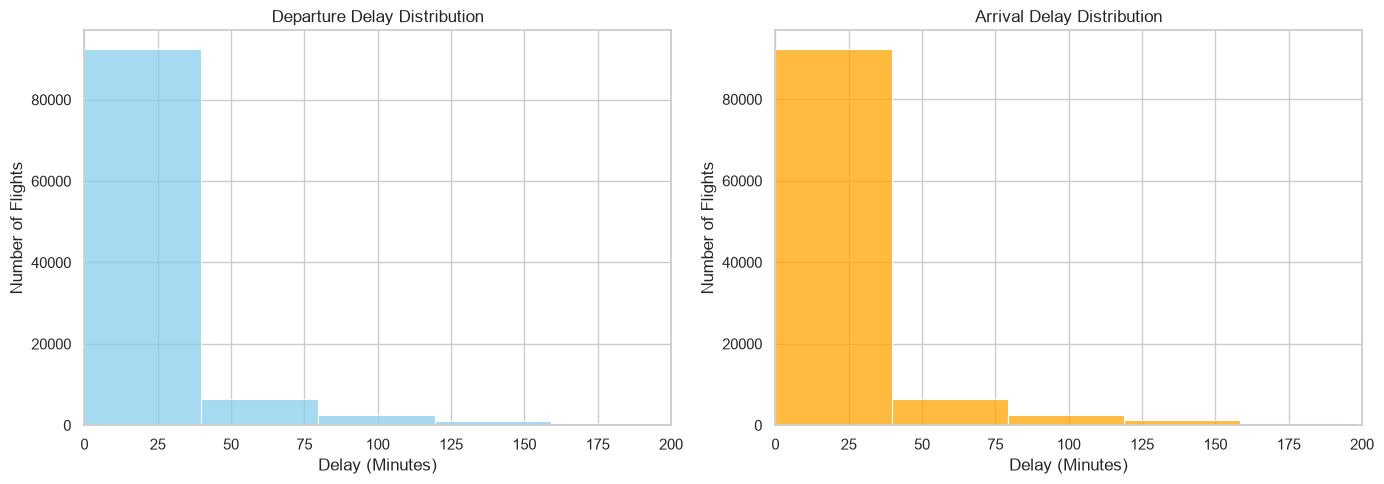

In [40]:

# Improved Graph 3: Departure and Arrival Delay Distributions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df_clean,
    x="Departure Delay in Minutes",
    bins=40,
    ax=axes[0],
    color="skyblue"
)
axes[0].set_title("Departure Delay Distribution")
axes[0].set_xlabel("Delay (Minutes)")
axes[0].set_ylabel("Number of Flights")
axes[0].set_xlim(0, 200)

sns.histplot(
    data=df_clean,
    x="Arrival Delay in Minutes",
    bins=40,
    ax=axes[1],
    color="orange"
)
axes[1].set_title("Arrival Delay Distribution")
axes[1].set_xlabel("Delay (Minutes)")
axes[1].set_ylabel("Number of Flights")
axes[1].set_xlim(0, 200)

plt.tight_layout()

# Save the improved visualization
visual_dir = Path("visualizations")
visual_dir.mkdir(exist_ok=True)

plt.savefig(
    visual_dir / "flight_delay_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Graph 3: Distribution of Flight Delays

**Observation:** Most flights have relatively short delays, while the frequency of longer delays decreases.

**Interpretation:** The delay distribution is concentrated in the lower-minute ranges, with fewer flights experiencing longer delays.

**Business Insight:** Frequent short delays can affect passenger experience and overall airline punctuality.

**Recommendation:** Monitor departure and arrival delays, investigate the causes using additional operational data, and identify opportunities to improve on-time performance.

In [41]:

# Final Numerical Analysis

print("DATASET SUMMARY")
print("Total passengers:", len(df_clean))
print("Total columns after cleaning:", df_clean.shape[1])

print("\nSATISFACTION PERCENTAGE")
display(
    (df_clean["satisfaction"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nSATISFACTION BY CLASS (%)")
display(class_satisfaction.round(2))

print("\nFLIGHT DELAY SUMMARY (minutes)")
delay_summary = df_clean[
    ["Departure Delay in Minutes", "Arrival Delay in Minutes"]
].describe().round(2)

display(delay_summary)

print("\nPASSENGERS WITH DELAYS OVER 15 MINUTES")
print(
    "Departure:",
    (df_clean["Departure Delay in Minutes"] > 15).sum()
)
print(
    "Arrival:",
    (df_clean["Arrival Delay in Minutes"] > 15).sum()
)


DATASET SUMMARY
Total passengers: 103904
Total columns after cleaning: 24

SATISFACTION PERCENTAGE


satisfaction
neutral or dissatisfied    56.67
satisfied                  43.33
Name: proportion, dtype: float64


SATISFACTION BY CLASS (%)


satisfaction,neutral or dissatisfied,satisfied
Class,,
Business,30.57,69.43
Eco,81.39,18.61
Eco Plus,75.39,24.61



FLIGHT DELAY SUMMARY (minutes)


,Departure Delay in Minutes,Arrival Delay in Minutes
count,103904.00,103904.00
mean,14.82,15.13
std,38.23,38.65
min,0.00,0.00
25%,0.00,0.00
50%,0.00,0.00
75%,12.00,13.00
max,1592.00,1584.00



PASSENGERS WITH DELAYS OVER 15 MINUTES
Departure: 23052
Arrival: 23635


## Final Conclusion

The exploratory data analysis was performed on 103,904 airline passenger records with 24 columns after removing an unnecessary index column and handling missing arrival-delay values.

The analysis revealed that 56.67% of passengers were neutral or dissatisfied, while 43.33% were satisfied. Business Class had the highest satisfaction rate at 69.43%, whereas Eco Class had the lowest at 18.61%.

The average departure delay was 14.82 minutes, and the average arrival delay was 15.13 minutes. A substantial number of records showed delays exceeding 15 minutes.

### Recommendations
1. Investigate the factors contributing to low satisfaction among Eco Class passengers.
2. Review service ratings such as online boarding, seat comfort, food and drink, and in-flight entertainment.
3. Monitor departure and arrival delays to identify opportunities to improve punctuality.
4. Use additional operational data to investigate the causes of long delays.
5. Collect loyalty-program and delay-reason data for deeper future analysis.

**Project Outcome:** The analysis identified differences in passenger satisfaction across travel classes and summarized flight delay patterns to support data-driven service improvement.

In [42]:
from pathlib import Path

visual_dir = Path("visualizations")
visual_dir.mkdir(exist_ok=True)

print("Visualization folder created:", visual_dir.resolve())


Visualization folder created: /Users/pragya/Desktop/Airlines_EDA_Project/visualizations


In [43]:
plt.savefig(visual_dir / "satisfaction_distribution.png",
            dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [44]:
plt.savefig(visual_dir / "class_satisfaction.png",
            dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [45]:
plt.savefig(visual_dir / "flight_delay_distribution.png",
            dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>